In [2]:
import pandas as pd

In [4]:
df = pd.read_csv('course_lead_scoring_2026.csv')

In [5]:
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NaN,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   object 
 1   industry                  4760 non-null   object 
 2   employment_status         4806 non-null   object 
 3   location                  4792 non-null   object 
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 351.7+ KB


#### Check if the missing values are presented in the features.  
#### If there are missing values:  
#### For categorical features, replace them with 'NA'  
#### For numerical features, replace with with 0.0  

In [7]:
df['lead_source'] = df['lead_source'].fillna('NA')

In [9]:
df['industry'] = df['industry'].fillna('NA')

In [10]:
df['employment_status'] = df['employment_status'].fillna('NA')

In [11]:
df['location'] = df['location'].fillna('NA')

In [12]:
df['annual_income'] = df['annual_income'].fillna('0.0')

In [13]:
df['lead_score'] = df['lead_score'].fillna('0.0')

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   lead_source               5000 non-null   object
 1   industry                  5000 non-null   object
 2   employment_status         5000 non-null   object
 3   location                  5000 non-null   object
 4   annual_income             5000 non-null   object
 5   number_of_courses_viewed  5000 non-null   int64 
 6   interaction_count         5000 non-null   int64 
 7   lead_score                5000 non-null   object
 8   converted                 5000 non-null   int64 
dtypes: int64(3), object(6)
memory usage: 351.7+ KB


## Question 1

#### What is the most frequent observation (mode) for the column industry?

In [16]:
df['industry'].count()

np.int64(5000)

In [18]:
df['industry'].value_counts()

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NA                240
Name: count, dtype: int64

## Question 2

#### Create the correlation matrix for the numerical features of your dataset. In a correlation matrix, you compute the correlation coefficient between every pair of features.  
#### What are the two features that have the biggest correlation?  

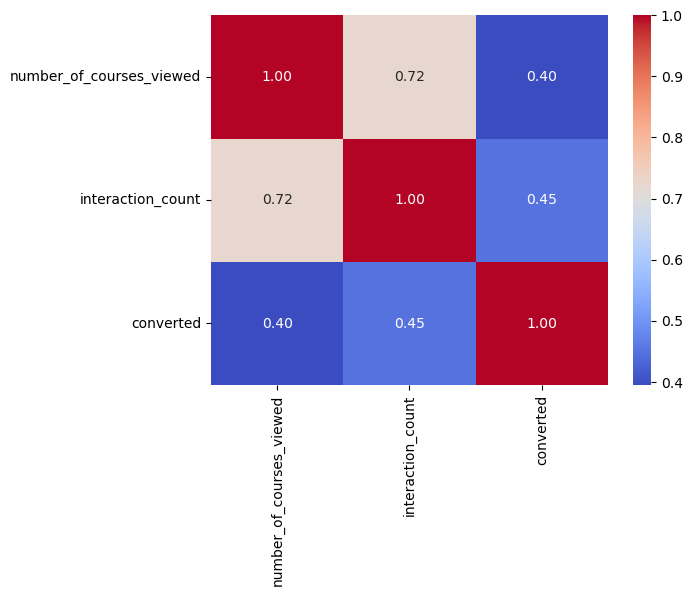

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df.corr(numeric_only=True)

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

In [24]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42
)

## Question 3

#### Calculate the mutual information score between converted and other categorical variables in the dataset. Use the training set only.  
#### Round the scores to 2 decimals using round(score, 2).  

In [28]:
from sklearn.metrics import mutual_info_score

categorical = df_train.select_dtypes(
    include=['object', 'category', 'bool']
).columns.drop('converted', errors='ignore')

for c in categorical:
    score = mutual_info_score(
        df_train['converted'].astype(str),
        df_train[c].fillna('missing').astype(str)
    )
    print(c, round(score, 2))

lead_source 0.03
industry 0.0
employment_status 0.02
location 0.0
annual_income 0.6
lead_score 0.15


## Question 4

#### Now let's train a logistic regression.  
#### Remember that we have several categorical variables in the dataset. Include them using one-hot encoding.  
#### Fit the model on the training dataset.  
#### To make sure the results are reproducible across different versions of Scikit-Learn, fit the model with these parameters:  
#### model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)  
#### Calculate the accuracy on the validation dataset and round it to 2 decimal digits.  

In [30]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Separate target from features
y_train = df_train['converted']
y_val = df_val['converted']

X_train = df_train.drop(columns=['converted'])
X_val = df_val.drop(columns=['converted'])

# One-hot encode categorical variables
dv = DictVectorizer(sparse=False)

train_dicts = X_train.to_dict(orient='records')
val_dicts = X_val.to_dict(orient='records')

X_train_encoded = dv.fit_transform(train_dicts)
X_val_encoded = dv.transform(val_dicts)

# Train logistic regression
model = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000,
    random_state=42
)

model.fit(X_train_encoded, y_train)

# Validate
y_pred = model.predict(X_val_encoded)
accuracy = accuracy_score(y_val, y_pred)

print(round(accuracy, 2))

0.65


## Question 5

#### Let's find the least useful feature using the feature elimination technique.  
#### Train a model using the same features and parameters as in Q4 (without rounding).  
#### Now exclude each feature from this set and train a model without it. Record the accuracy for each model.  
#### For each feature, calculate the difference between the original accuracy and the accuracy without the feature.  

In [31]:
import pandas as pd
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Separate target and features
y_train = df_train['converted']
y_val = df_val['converted']

X_train = df_train.drop(columns=['converted'])
X_val = df_val.drop(columns=['converted'])

def train_and_evaluate(features):
    dv = DictVectorizer(sparse=False)

    train_dicts = features['train'].to_dict(orient='records')
    val_dicts = features['val'].to_dict(orient='records')

    X_train_encoded = dv.fit_transform(train_dicts)
    X_val_encoded = dv.transform(val_dicts)

    model = LogisticRegression(
        solver='liblinear',
        C=1.0,
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train_encoded, y_train)
    y_pred = model.predict(X_val_encoded)

    return accuracy_score(y_val, y_pred)

# Original accuracy using all features
original_accuracy = train_and_evaluate({
    'train': X_train,
    'val': X_val
})

print("Original accuracy:", original_accuracy)

# Exclude each feature, one at a time
results = []

for feature in X_train.columns:
    X_train_reduced = X_train.drop(columns=[feature])
    X_val_reduced = X_val.drop(columns=[feature])

    reduced_accuracy = train_and_evaluate({
        'train': X_train_reduced,
        'val': X_val_reduced
    })

    results.append({
        'excluded_feature': feature,
        'accuracy_without_feature': reduced_accuracy,
        'difference': original_accuracy - reduced_accuracy
    })

results_df = pd.DataFrame(results)
print(results_df.sort_values('difference'))

Original accuracy: 0.645
           excluded_feature  accuracy_without_feature  difference
4             annual_income                     0.727      -0.082
1                  industry                     0.645       0.000
2         employment_status                     0.645       0.000
3                  location                     0.645       0.000
7                lead_score                     0.644       0.001
5  number_of_courses_viewed                     0.643       0.002
0               lead_source                     0.642       0.003
6         interaction_count                     0.600       0.045


## Question 6

#### Now let's train a regularized logistic regression.  
#### Let's try the following values of the parameter C: [0.000001, 0.00001, 0.0001, 0.001].  
#### Train models using all the features as in Q4.  
#### Calculate the accuracy on the validation dataset and round it to 3 decimal digits.  

In [33]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Separate target and features
y_train = df_train['converted']
y_val = df_val['converted']

X_train = df_train.drop(columns=['converted'])
X_val = df_val.drop(columns=['converted'])

# One-hot encode features
dv = DictVectorizer(sparse=False)

X_train_encoded = dv.fit_transform(
    X_train.to_dict(orient='records')
)
X_val_encoded = dv.transform(
    X_val.to_dict(orient='records')
)

# Try different C values
for C in [0.000001, 0.00001, 0.0001, 0.001]:
    model = LogisticRegression(
        solver='liblinear',
        C=C,
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train_encoded, y_train)
    y_pred = model.predict(X_val_encoded)

    accuracy = accuracy_score(y_val, y_pred)
    print(f'C={C}: {accuracy:.3f}')

C=1e-06: 0.598
C=1e-05: 0.598
C=0.0001: 0.613
C=0.001: 0.645
